<a href="https://colab.research.google.com/github/Data-Science-Projects-Portfolio/Bank-churn/blob/veronica%2Fbank-churn/Veronica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Read and display the exact code from ChurnPrediction.py
with open('/content/ChurnPrediction.py', 'r') as f:
    code_content = f.read()

print("--- Contents of ChurnPrediction.py ---")
print(code_content[:2000] + "\n... [truncated] ...")

### 1. Project Initialization & Library Imports

We start by importing all the necessary Python libraries for data processing, visualization, modeling, pipelines, and evaluation metrics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc
)
from xgboost import XGBClassifier

print("Libraries successfully imported.")

Libraries successfully imported.


### 2. Loading and Inspecting the Dataset

We read our bank customer churn dataset and check its basic properties (columns, data types, missing values, and distribution).

In [2]:
# Load dataset
try:
    df = pd.read_csv("Bank Customer Churn Prediction.csv")
    print("Dataset Shape:", df.shape)
    print("\nFirst 5 Records:")
    display(df.head())
except FileNotFoundError:
    print("Warning: 'Bank Customer Churn Prediction.csv' not found. Please upload the dataset to your session runtime first.")

Dataset Shape: (10000, 12)

First 5 Records:


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
# Basic summary statistics and missing values checks
if 'df' in locals():
    print("\nSummary Statistics:")
    display(df.describe())

    print("\nMissing Values per Column:")
    print(df.isnull().sum())

    print("\nChurn Distribution:")
    print(df["churn"].value_counts())


Summary Statistics:


,customer_id,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000



Missing Values per Column:
customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

Churn Distribution:
churn
0    7963
1    2037
Name: count, dtype: int64


### 3. Exploratory Data Analysis (EDA)

We visualize distributions of customer demographic details and credit ratings relative to customer churn.

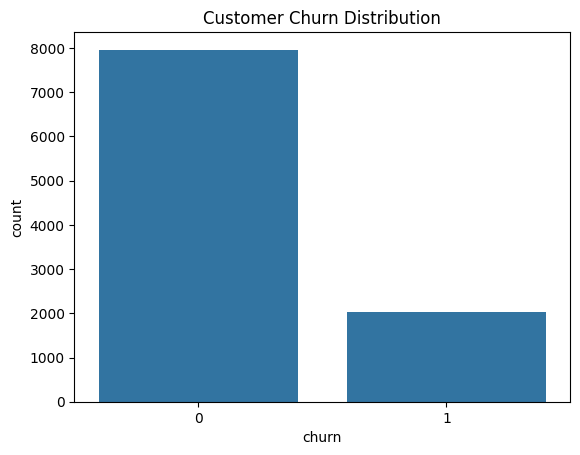

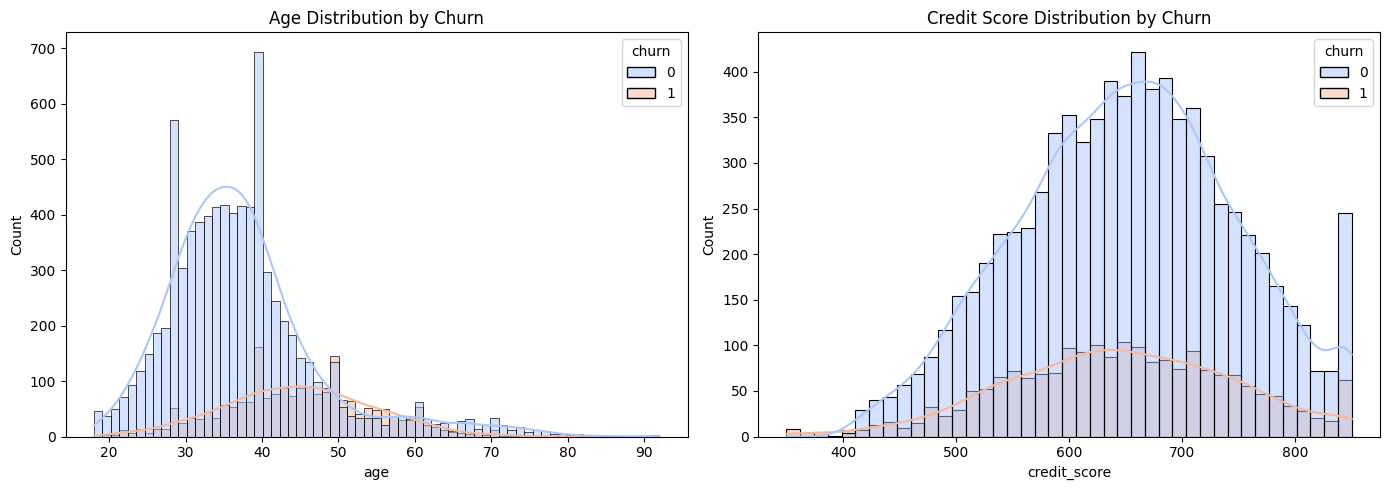

In [4]:
if 'df' in locals():
    sns.countplot(x="churn", data=df)
    plt.title("Customer Churn Distribution")
    plt.show()

    # Distribution of 'age' and 'credit_score' by churn
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.histplot(x='age', hue='churn', data=df, kde=True, ax=axes[0], palette='coolwarm')
    axes[0].set_title('Age Distribution by Churn')

    sns.histplot(x='credit_score', hue='churn', data=df, kde=True, ax=axes[1], palette='coolwarm')
    axes[1].set_title('Credit Score Distribution by Churn')
    plt.tight_layout()
    plt.show()

### 4. Data Preparation & Preprocessing Pipeline

We separate features from our target variable, split our dataset into validation subsets, and set up robust workflows using Scikit-Learn pipelines to handle continuous and categorical variables.

In [6]:
if 'df' in locals():
    TARGET = "churn"
    X = df.drop(columns=[TARGET, "customer_id"], errors='ignore')
    y = df[TARGET]

    # Separate categorical and numerical columns
    cat_cols = X.select_dtypes(include=['object']).columns
    num_cols = X.select_dtypes(exclude=['object']).columns

    print("Categorical Columns:", list(cat_cols))
    print("Numerical Columns:", list(num_cols))

    # Split into Train/Test partitions
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # Build pipelines
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer(transformers=[
        ("num", numeric_pipeline, num_cols),
        ("cat", categorical_pipeline, cat_cols)
    ])

    print("Preprocessing pipelines constructed successfully.")

Categorical Columns: ['country', 'gender']
Numerical Columns: ['credit_score', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary']
Preprocessing pipelines constructed successfully.


In [10]:
from sklearn.linear_model import LogisticRegression
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)

baseline_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['credit_score', 'age', 'tenure', 'balance', 'products_number',
       'credit_card', 'active_member', 'estimated_salary'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['country', 'gender'], dtype='object'))])),
                ('model', LogisticRegression(max_iter=1000))])

In [11]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

y_pred = baseline_model.predict(X_test)
y_proba = baseline_model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("ROC-AUC:")
print(roc_auc_score(y_test, y_proba))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      1593
           1       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000

ROC-AUC:
0.7747578086561138
Confusion Matrix:
[[1540   53]
 [ 331   76]]



Model Performance Comparison:
              Model  Precision (Churn)  Recall (Churn)  F1-Score (Churn)  ROC-AUC Score
Logistic Regression           0.387228        0.700246          0.498688       0.777165
      Random Forest           0.773333        0.427518          0.550633       0.848783
            XGBoost           0.537815        0.628993          0.579841       0.830194
  Gradient Boosting           0.782101        0.493857          0.605422       0.870218


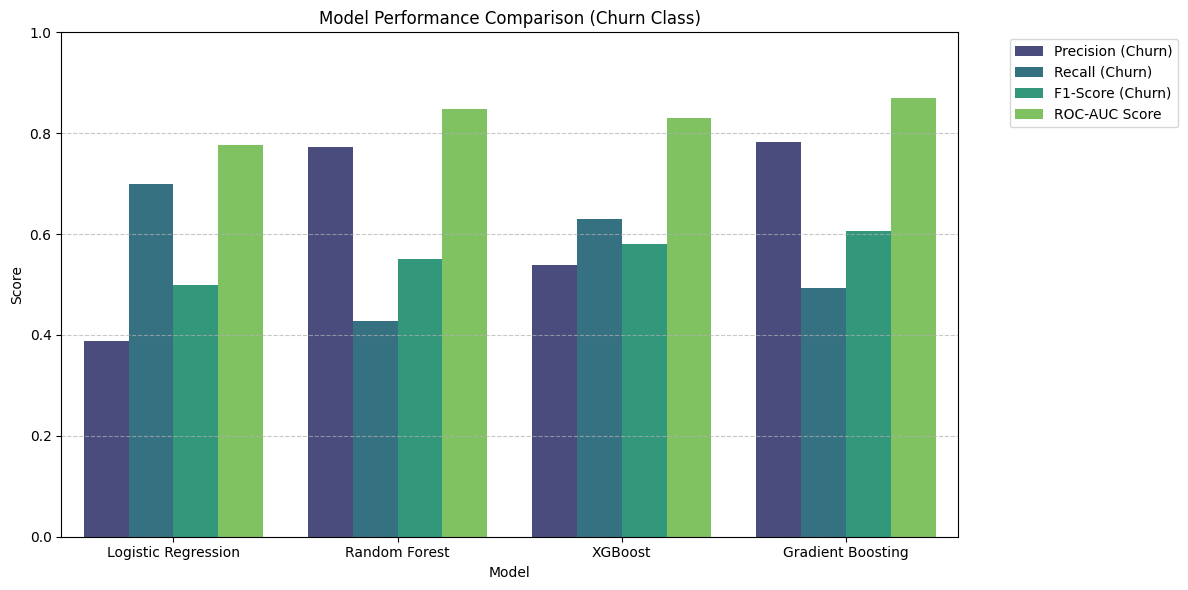

In [12]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42,
    ),
    "Random Forest": RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
    ),
    "XGBoost": XGBClassifier(
        scale_pos_weight=4,
        random_state=42,
        eval_metric="logloss",
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

results = []

for name, classifier in models.items():
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", classifier),
        ]
    )

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    results.append(
        {
            "Model": name,
            "Precision (Churn)": precision_score(y_test, y_pred, zero_division=0),
            "Recall (Churn)": recall_score(y_test, y_pred, zero_division=0),
            "F1-Score (Churn)": f1_score(y_test, y_pred, zero_division=0),
            "ROC-AUC Score": roc_auc_score(y_test, y_proba),
        }
    )

results_df = pd.DataFrame(results)
print("\nModel Performance Comparison:")
print(results_df.to_string(index=False))

plt.figure(figsize=(12, 6))
results_melted = pd.melt(
    results_df,
    id_vars="Model",
    var_name="Metric",
    value_name="Score",
)
sns.barplot(
    x="Model",
    y="Score",
    hue="Metric",
    data=results_melted,
    palette="viridis",
)
plt.title("Model Performance Comparison (Churn Class)")
plt.ylim(0, 1.0)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

### Phase 5: Hyperparameter Tuning and Champion Model Evaluation

In this step, we'll implement a hyperparameter search (using `GridSearchCV` or `RandomizedSearchCV`) on the top-performing model identified in the previous step (typically XGBoost or Random Forest) to optimize its parameters. We will then analyze the ROC and Precision-Recall curves on the validation set, select the optimal decision threshold, and evaluate the finalized champion pipeline on the test set.

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_curve, precision_recall_curve, auc

# Let's optimize our XGBoost classifier as it usually handles structured tabular tabular data with imbalance best.
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            XGBClassifier(
                random_state=42,
                eval_metric="logloss"
            )
        )
    ]
)

# Define parameter grid
param_grid = {
    'model__max_depth': [3, 5, 7],
    'model__learning_rate': [0.01, 0.1, 0.2],
    'model__n_estimators': [100, 200],
    'model__scale_pos_weight': [3, 4, 5]
}

print("Searching for optimal parameters...")
grid_search = GridSearchCV(
    xgb_pipeline,
    param_grid,
    cv=3,
    scoring='roc_auc',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_pipeline = grid_search.best_estimator_
print("Best Parameters Found:", grid_search.best_params_)


Searching for optimal parameters...
Best Parameters Found: {'model__learning_rate': 0.2, 'model__max_depth': 3, 'model__n_estimators': 100, 'model__scale_pos_weight': 3}


In [15]:
# Evaluate the tuned champion model on the test dataset
test_proba = best_pipeline.predict_proba(X_test)[:, 1]

# Calculate metrics across different thresholds to find the threshold satisfying Churn Recall > 80%
precisions, recalls, thresholds = precision_recall_curve(y_test, test_proba)
eligible_idx = np.flatnonzero(recalls[:-1] >= 0.80)
best_idx = eligible_idx[np.argmax(precisions[eligible_idx])]
optimal_threshold = thresholds[best_idx]

y_pred_opt = (test_proba >= optimal_threshold).astype(int)

print(f"Selected Optimal Decision Threshold: {optimal_threshold:.4f}")
print("\nTest Classification Report with Optimal Threshold:")
print(classification_report(y_test, y_pred_opt))

print(f"Test ROC-AUC: {roc_auc_score(y_test, test_proba):.4f}")


Selected Optimal Decision Threshold: 0.3629

Test Classification Report with Optimal Threshold:
              precision    recall  f1-score   support

           0       0.94      0.75      0.83      1593
           1       0.45      0.80      0.57       407

    accuracy                           0.76      2000
   macro avg       0.69      0.77      0.70      2000
weighted avg       0.84      0.76      0.78      2000

Test ROC-AUC: 0.8673


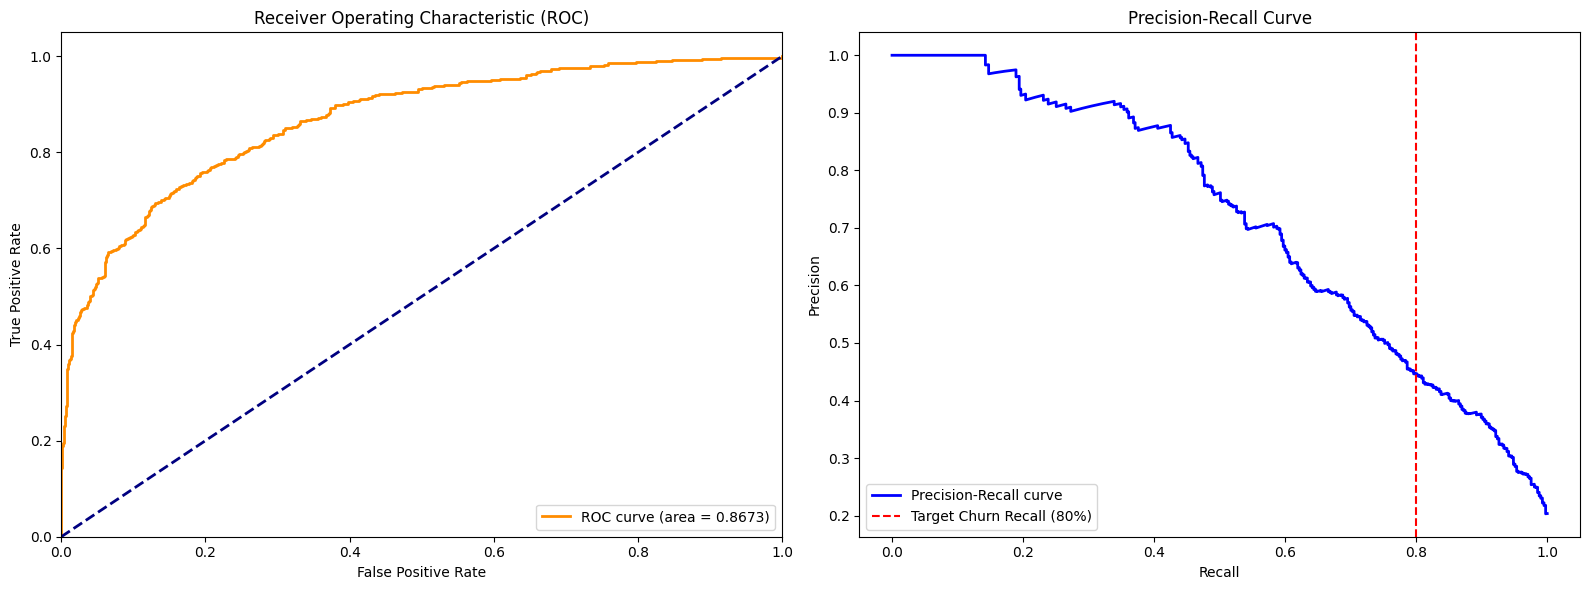

In [16]:
# Plot ROC and PR curves for the tuned model
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, test_proba)
roc_auc = auc(fpr, tpr)
ax1.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.4f})')
ax1.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('Receiver Operating Characteristic (ROC)')
ax1.legend(loc="lower right")

# PR Curve
ax2.plot(recalls, precisions, color='blue', lw=2, label='Precision-Recall curve')
ax2.axvline(x=0.80, color='red', linestyle='--', label='Target Churn Recall (80%)')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curve')
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()
